# Comparación estadística de los modelos de referencia

Con 140 modelos, el número de comparaciones pareadas posibles es 9.730, y aplicarlas sin control
produciría cerca de 487 falsos positivos al 5 %. La comparación sigue por eso una secuencia
jerárquica: una prueba global, un análisis post-hoc con control del error familiar, comparaciones
dirigidas entre finalistas con corrección de Holm y tamaños del efecto. Como los bloques de
validación comparten entrenamiento y los días de prueba no son independientes, se privilegian
las pruebas que respetan esa dependencia.

In [1]:
# Resultados por bloque, modelos finales y resultados de scripts/estadistica.py
import sys, json, pickle, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from myst_nb import glue
from sklearn.metrics import average_precision_score, roc_auc_score
from src import estilo
from src.estilo import RIO, SED, CAU, ALE, NEU
from src.config import RESULTADOS
from src.analysis import tabla_pliegues
from src.models import NOMBRES_MODELO
from src.stats_tests import (friedman, nemenyi, delong, holm, bootstrap_bloques, longitud_bloque, delta_cliff,
                             magnitud_cliff, wilcoxon_holm)
from src.experiment import cargar_datos
D = cargar_datos(); E = RESULTADOS / "estadistica"
pl = tabla_pliegues("clf_calamar")
mejores = pd.read_csv(RESULTADOS / "mejores_clf.csv")
fin = {r["modelo"]: r for r in pickle.load(open(RESULTADOS / "final_clf.pkl", "rb"))}

## Clasificación

### Etapa 1: prueba global sobre las 112 combinaciones

La tabla muestra los quince mejores rangos medios entre las 112 combinaciones, ordenadas dentro
de cada uno de los doce bloques externos.

In [2]:
# Friedman y Nemenyi sobre las 112 combinaciones: rangos medios de las quince primeras
c112 = json.loads((E / "cd_112.json").read_text(encoding="utf-8"))
for k in ("chi2", "p", "cd", "pares_signif", "pares_total", "gl"):
    glue(f"c112_{k}", c112[k], display=False)
pd.DataFrame({"rango medio": c112["rangos_top"]}).rename(index=lambda c: " · ".join(c.split(" | "))).round(2)

,rango medio
random_forest · ninguno · grid,18.92
random_forest · ninguno · bayes,21.67
random_forest · ninguno · genetico,21.92
random_forest · ninguno · random,22.33
random_forest · smote · grid,22.58
random_forest · smote · genetico,23.58
random_forest · balanced · grid,24.50
xgboost · smote · genetico,24.83
random_forest · smote · random,24.83
random_forest · balanced · random,26.58


La prueba de Friedman sobre los doce bloques externos rechaza que las 112 combinaciones tengan
el mismo rango medio (χ² = {glue:text}`c112_chi2:.1f` con {glue:text}`c112_gl` grados de
libertad, p = {glue:text}`c112_p:.2g`). La diferencia crítica de Nemenyi con 112 modelos y doce
bloques es de {glue:text}`c112_cd:.1f` rangos, y solo {glue:text}`c112_pares_signif:,` de los
{glue:text}`c112_pares_total:,` pares la superan. Con doce bloques y 112 modelos, el control del
error familiar vuelve indistinguibles casi todas las combinaciones vecinas; la potencia de la
prueba se concentra en las diferencias extremas, y la comparación informativa debe hacerse entre
finalistas.

### Etapa 2: diagrama de diferencia crítica entre los mejores de cada modelo

La {numref}`fig-cd-bench` repite la prueba solo con la mejor combinación de cada modelo, que es
la comparación de interés.

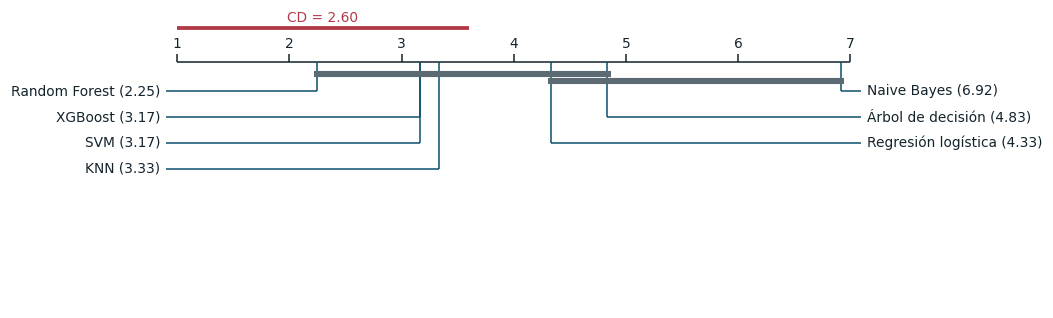

In [3]:
# Diagrama de diferencia crítica de los siete modelos de referencia
tabla = pd.read_csv(E / "universo_pliegues.csv", index_col=0).drop(columns="original")
fr = friedman(tabla); ne = nemenyi(fr["rangos"], fr["n_bloques"])
from src.estilo import dibujar_cd
fig, ax = plt.subplots(figsize=(10, 3.4)); dibujar_cd(fr["rangos"], ne["cd"], ax=ax, nombres=NOMBRES_MODELO); plt.show()
glue("fr7_chi2", fr["chi2"], display=False); glue("fr7_p", fr["p"], display=False); glue("cd7", ne["cd"], display=False)
glue("fr7_ff", fr["F_iman_davenport"], display=False); glue("fr7_pff", fr["p_iman_davenport"], display=False)

La tabla siguiente detalla cada comparación por pares.

In [4]:
# Comparaciones por pares de Nemenyi entre los siete modelos
ne["pares"].assign(modelo_a=lambda d: d.modelo_a.map(NOMBRES_MODELO), modelo_b=lambda d: d.modelo_b.map(NOMBRES_MODELO)).sort_values("p_nemenyi").round(4)

,modelo_a,modelo_b,dif_rangos,p_nemenyi,significativo
5,Random Forest,Naive Bayes,4.6667,0.0000,True
10,XGBoost,Naive Bayes,3.7500,0.0004,True
14,SVM,Naive Bayes,3.7500,0.0004,True
17,KNN,Naive Bayes,3.5833,0.0010,True
19,Regresión logística,Naive Bayes,2.5833,0.0528,False
4,Random Forest,Árbol de decisión,2.5833,0.0528,False
20,Árbol de decisión,Naive Bayes,2.0833,0.2148,False
3,Random Forest,Regresión logística,2.0833,0.2148,False
9,XGBoost,Árbol de decisión,1.6667,0.4871,False
13,SVM,Árbol de decisión,1.6667,0.4871,False


Entre las mejores combinaciones de los siete modelos, Friedman rechaza la igualdad
(χ² = {glue:text}`fr7_chi2:.1f`, p = {glue:text}`fr7_p:.2g`; la corrección F de Iman y Davenport
da {glue:text}`fr7_ff:.1f`), pero la diferencia crítica de {glue:text}`cd7:.2f` rangos solo separa
a Naive Bayes de los cuatro mejores modelos. Random Forest, XGBoost, SVM y KNN forman un grupo
estadísticamente indistinguible, al que se suman la regresión logística y el árbol en el límite
de la significancia. El ordenamiento de los modelos de referencia es, por tanto, robusto en sus
extremos y difuso en el centro.

### Comparaciones dirigidas en la prueba reservada: DeLong con Holm

La tabla compara los tres mejores modelos en la prueba reservada con la prueba de DeLong y, en
paralelo, con un intervalo de bootstrap por bloques para la misma diferencia de AUC.

In [5]:
# DeLong frente a bootstrap estacionario para la diferencia de ROC-AUC entre los tres mejores modelos
y = D.y_clf_test.values
top = mejores.sort_values("pr_auc_mean", ascending=False).modelo.head(3).tolist()
filas = []
L = longitud_bloque(y.astype(float))
for i in range(3):
    for j in range(i + 1, 3):
        a, b = top[i], top[j]
        dl = delong(y, fin[a]["pred_test"], fin[b]["pred_test"])
        ic = bootstrap_bloques(lambda yy, s1, s2: roc_auc_score(yy, s1) - roc_auc_score(yy, s2), y,
                               fin[a]["pred_test"], fin[b]["pred_test"], media_bloque=L, n_boot=1000)
        filas.append({"Modelo A": NOMBRES_MODELO[a], "Modelo B": NOMBRES_MODELO[b], "Δ AUC": dl["dif"],
                      "IC 95 % bootstrap por bloques (BCa)": f"[{ic['ic_inf']:.4f}; {ic['ic_sup']:.4f}]",
                      "z (DeLong)": dl["z"], "p crudo": dl["p"]})
dt = pd.DataFrame(filas); dt["p ajustado (Holm)"] = holm(dt["p crudo"].values)
glue("L_test", L, display=False)
dt.round(4)

,Modelo A,Modelo B,Δ AUC,IC 95 % bootstrap por bloques (BCa),z (DeLong),p crudo,p ajustado (Holm)
0,Random Forest,XGBoost,0.0009,[-0.0019; 0.0042],1.4743,0.1404,0.1404
1,Random Forest,KNN,0.0037,[-0.0009; 0.0113],3.5637,0.0004,0.0011
2,XGBoost,KNN,0.0028,[-0.0030; 0.0101],2.4796,0.0132,0.0263


La prueba de DeLong sobre la prueba reservada no distingue a Random Forest de XGBoost
(p ajustado de 0,14), pero sí declara significativas sus ventajas sobre KNN, y la de XGBoost
sobre KNN, tras la corrección de Holm. El intervalo de confianza por bootstrap estacionario de la
misma diferencia de AUC, en cambio, contiene el cero en los tres casos. La discrepancia se debe a
que DeLong estima la varianza del AUC suponiendo que los días de prueba son independientes; con
una autocorrelación de 0,99 la muestra efectiva es mucho menor que los 5.946 días, y sus p-valores
resultan optimistas. Por esa razón DeLong se reporta solo como prueba complementaria, y las
conclusiones se apoyan en el bootstrap por bloques (con longitud media de {glue:text}`L_test`
días) y en las pruebas sobre bloques externos.

### Intervalos de confianza y tamaños del efecto

Las dos tablas siguientes muestran los intervalos de confianza por bloques de las métricas de
cada modelo en la prueba y la comparación del mejor modelo con cada uno de los demás sobre los
doce bloques externos.

In [6]:
# IC 95 % por bootstrap estacionario en la prueba; Wilcoxon-Holm y δ de Cliff sobre los 12 bloques
filas = []
for m in mejores.sort_values("pr_auc_mean", ascending=False).modelo:
    s = fin[m]["pred_test"]
    for nombre, f in (("PR-AUC", average_precision_score), ("ROC-AUC", roc_auc_score)):
        ic = bootstrap_bloques(f, y, s, media_bloque=L, n_boot=1000)
        filas.append({"Modelo": NOMBRES_MODELO[m], "Métrica": nombre, "Estimación": ic["estimacion"],
                      "IC 95 % inferior": ic["ic_inf"], "IC 95 % superior": ic["ic_sup"]})
ics = pd.DataFrame(filas)
ref = mejores.sort_values("pr_auc_mean", ascending=False).iloc[0].modelo
w = wilcoxon_holm(tabla, ref)
w["modelo"] = w.modelo.map(NOMBRES_MODELO); w["magnitud"] = w.delta_cliff.map(magnitud_cliff)
glue("ref_bench", NOMBRES_MODELO[ref], display=False)
display(ics.round(4))
w[["modelo", "dif_media", "victorias", "p", "p_holm", "delta_cliff", "magnitud"]].round(4)

,Modelo,Métrica,Estimación,IC 95 % inferior,IC 95 % superior
0,Random Forest,PR-AUC,0.9495,0.9110,0.9713
1,Random Forest,ROC-AUC,0.9806,0.9711,0.9874
2,XGBoost,PR-AUC,0.9411,0.8807,0.9647
3,XGBoost,ROC-AUC,0.9797,0.9703,0.9871
4,KNN,PR-AUC,0.9377,0.8879,0.9679
5,KNN,ROC-AUC,0.9769,0.9623,0.9864
6,SVM,PR-AUC,0.9496,0.9081,0.9755
7,SVM,ROC-AUC,0.9801,0.9689,0.9891
8,Árbol de decisión,PR-AUC,0.8959,0.8235,0.9342
9,Árbol de decisión,ROC-AUC,0.9604,0.9419,0.9751


,modelo,dif_media,victorias,p,p_holm,delta_cliff,magnitud
5,Naive Bayes,0.2046,12,0.0002,0.0015,0.7917,grande
3,Árbol de decisión,0.0443,11,0.0005,0.0024,0.3194,pequeño
4,Regresión logística,0.0599,10,0.0061,0.0244,0.2778,pequeño
1,KNN,0.0220,8,0.0881,0.2644,0.1250,despreciable
0,XGBoost,0.0054,9,0.1167,0.2644,0.1111,despreciable
2,SVM,0.0241,7,0.1506,0.2644,0.0694,despreciable


Los intervalos de la PR-AUC en la prueba se solapan ampliamente entre los cuatro mejores modelos.
La comparación de {glue:text}`ref_bench` con cada modelo mediante Wilcoxon con Holm sobre los
doce bloques confirma la estructura del diagrama de diferencia crítica: la ventaja es
significativa y de tamaño no despreciable frente a Naive Bayes (δ de Cliff grande), el árbol de
decisión y la regresión logística (pequeño), y no lo es frente a KNN, XGBoost ni SVM, con tamaños
del efecto despreciables. Entre los mejores modelos, por tanto, las diferencias observadas son
menores que la variabilidad entre bloques, y elegir a Random Forest como referencia para el modelo
propuesto es una decisión por media, no una superioridad demostrada.

## Regresión: secuencia jerárquica

### Model Confidence Set

La tabla muestra, para cada una de las 28 combinaciones de regresión, su error, su rango medio de
pérdida y si pertenece al conjunto de modelos que no pueden distinguirse del mejor.

In [7]:
# Model Confidence Set de Hansen (α = 0,10) sobre la pérdida cuadrática fuera de muestra
mcs = pd.read_csv(E / "mcs_regresion.csv")
glue("mcs_n", int((mcs["¿En el conjunto?"] == "Sí").sum()), display=False)
glue("mcs_mejor", mcs.iloc[0]["Combinación"], display=False)
mcs

,Combinación,RMSE (m³/s),Rango medio de pérdida,p-valor MCS,¿En el conjunto?
0,svr|bayes,580.3,12.43,1.000,Sí
1,svr|random,584.0,12.58,0.604,Sí
2,xgboost|random,588.2,12.94,0.604,Sí
3,xgboost|genetico,590.4,13.05,0.604,Sí
4,svr|genetico,592.2,13.08,0.584,Sí
5,svr|grid,592.3,13.01,0.005,No
6,xgboost|bayes,604.9,13.75,0.044,No
7,random_forest|random,618.9,13.93,0.018,No
8,random_forest|genetico,622.1,13.89,0.018,No
9,xgboost|grid,626.1,14.40,0.000,No


El Model Confidence Set {cite}`hansen2011` parte de las 28 combinaciones y, con un bootstrap
estacionario sobre la pérdida cuadrática diaria de las predicciones fuera de muestra
(1986-2009), elimina iterativamente la peor mientras la hipótesis de igual capacidad predictiva
se rechace. Con α = 0,10, el conjunto de confianza retiene {glue:text}`mcs_n` combinaciones. Las
tablas siguientes comparan después a los finalistas entre sí y con la persistencia.

### Comparaciones dirigidas: Giacomini-White, Clark-West y Diebold-Mariano

In [8]:
# Diebold-Mariano (HLN) y Giacomini-White entre finalistas; Clark-West frente a la persistencia; SPA frente a Ridge
dirig = pd.read_csv(E / "regresion_dirigidas.csv")
cw = pd.read_csv(E / "regresion_clark_west.csv")
sp = json.loads((E / "spa_regresion.json").read_text(encoding="utf-8"))
display(dirig.round(4))
display(cw.round(4))
pd.Series(sp, name="SPA frente a Ridge").to_frame()

,modelo A,modelo B,DM-HLN,p DM,GW,p GW,Δ pérdida media (10⁶ m⁶/s²),IC 95 % bootstrap estacionario,d de Cohen,p DM (Holm),p GW (Holm)
0,svr|bayes,svr|random,-1.4750,0.1403,3.9196,0.1409,-0.0043,[-0.012; 0.002],-0.0503,0.4208,0.4227
1,svr|bayes,xgboost|random,-0.8108,0.4175,1.0844,0.5815,-0.0092,[-0.030; 0.014],-0.0240,0.5926,0.8826
2,svr|bayes,xgboost|genetico,-1.0445,0.2963,1.6361,0.4413,-0.0119,[-0.033; 0.011],-0.0308,0.5926,0.8826
3,svr|bayes,svr|genetico,-1.8323,0.0669,6.4587,0.0396,-0.0140,[-0.037; 0.006],-0.0782,0.2678,0.1583


,modelo general,modelo restringido,CW,p CW,RMSE general,RMSE persistencia,p CW (Holm)
0,svr|bayes,persistencia,10.8453,0.0,580.2886,1021.9871,0.0
1,svr|random,persistencia,10.8021,0.0,583.9562,1021.9871,0.0
2,xgboost|random,persistencia,10.7256,0.0,588.1657,1021.9871,0.0
3,xgboost|genetico,persistencia,10.7185,0.0,590.4435,1021.9871,0.0
4,svr|genetico,persistencia,10.7826,0.0,592.2084,1021.9871,0.0


,SPA frente a Ridge
lower,0.0005
consistent,0.0005
upper,0.0900
bloque,61.0000


La secuencia de regresión confirma lo que sugerían las métricas. El conjunto de confianza retiene
las combinaciones de SVR y XGBoost con optimización bayesiana, aleatoria y genética, y excluye a
Random Forest, a los modelos lineales, a KNN y a los árboles, cuyas pérdidas son significativamente
mayores. Entre los finalistas, ni Diebold-Mariano con la corrección de Harvey, Leybourne y Newbold
{cite}`harvey1997` ni Giacomini-White {cite}`giacomini2006` encuentran diferencias significativas
tras Holm, y los intervalos del bootstrap estacionario de la diferencia de pérdida contienen el
cero: SVR y XGBoost son estadísticamente equivalentes para predecir el caudal a quince días, con
tamaños de efecto despreciables (|d| < 0,08). La prueba de Clark-West, aplicada al único
anidamiento natural del problema, el de la persistencia ($\hat Q_{t+15} = Q_t$) dentro de los
modelos que usan el caudal actual, rechaza con claridad que los finalistas no mejoren sobre ella
{cite}`clark2007`. Finalmente, la prueba SPA de Hansen {cite}`hansen2005` con Ridge como
referencia da un p-valor consistente de 0,0005: hay al menos un modelo que supera de forma genuina
a la regresión lineal regularizada, y esa conclusión no es producto de haber probado muchos
modelos.